# Calibration

(If GitHub truncates the output, you can view the full notebook using [nbviewer](https://nbviewer.org/github/Kanato-Nakakuni/ComputationalMacro/blob/main/Lecture%20notes/Lec05_Calibration.ipynb).)

- Recall how we solved household decision problems: households optimize **taking factor prices and other parameters as given**.

- In general equilibrium (GE) models, factor prices are **endogenously determined**. In the last lecture, we learned how to compute them.

- So far, however, we have solved household problems and computed GE **by assigning arbitrary values to deep parameters** (e.g., the time discount factor).

- In this lecture, we learn how to determine these parameter values.

- This procedure, in the context of macroeconomics, is referred to as **Calibration**.  
  - A procedure to determine the parameter values of a quantitative macroeconomic model so that the model replicates key empirical regularities relevant to the research question at hand.  

In our model, the parameter values to be set include:

- Discount factor $\beta$  
- Relative weight on consumption $\omega$  
- Capital share $\alpha$  
- Depreciation rate $\delta$  
- Income replacement rate $\theta$  

---

### How?

Some parameters are taken directly from data or estimated outside the model.  

For example:
- The capital share $\alpha$ and depreciation rate $\delta$ are often obtained from national accounts data.  
- If the model includes a stochastic income process, its parameters are usually estimated using micro-level income data.  

Other parameters are calibrated so that the model replicates **targeted moments**—key empirical patterns.  
For example, in macroeconomic models:
- $\beta$ is often chosen so that the model implies a capital-output ratio $K/Y$ close to the one observed in data.  
- $\omega$ is often chosen so that the model replicates the share of time spent in leisure (or work) observed in data.

---

### Two-Step Calibration

We typically follow an approach often referred to as two-step calibration:  

1. **Step 1**: Set parameters based on external data or literature.  
2. **Step 2**: Determine remaining parameters so that the model replicates targeted moments.  

Researchers must decide which parameters fall into each step. This depends on:
- Whether the parameter is directly observable  
- Whether reliable empirical estimates are available  
- What is central to the research question (See below)  

---

### Example: Target Selection

Suppose we consider the pension income replacement rate $\theta$. It could be directly set using institutional data. However, many studies calibrate $\theta$ **within the model** so that it reproduces the **pension-to-GDP ratio**. This is particularly important when analyzing:  
- The macroeconomic consequences of demographic change
- Fiscal impacts of pension reform  

In those cases, the pension-to-GDP ratio is the key moment to match, not the raw value of $\theta$ itself.

---

### Calibration Strategy in Our Model

We follow this specific calibration procedure:

### Step 1: Externally Set Parameters

Set based on empirical consensus:  
- $\alpha = 0.33$  
- $\delta = 0.1$ (depends on the model’s period length)  
- $\sigma = 2.0$ (Literature)

### Step 2: Internally Calibrated Parameters

Choose values to match targeted moments:  
- $\beta$: calibrated so that $K/Y = 4.0$  
- $\omega$: chosen so that households work 1/3 of their available time  
- $\theta$: set so that the model replicates a pension-to-GDP ratio of 0.1 (i.e., 10% of GDP is spent on pensions)  

---

## Algorithm Outline

To implement calibration, we add an **outer loop** around the model solution:

1. Set $\alpha = 0.33$, $\delta = 0.1$, and $\sigma=2.0$. (1st step)  
<br>
2. Make initial guesses for parameters to determine in 2nd step $(\beta, \omega, \theta)$  
<br>
3. Solve the general equilibrium  
<br>
4. Compute the implied values of the targeted moments  
<br>
5. If the model moments do not match the targets, update the guesses and repeat until convergence  
---


### Procedure

1. Construct `struct` named Parameters, which contains (β, σ, ω, θ, α, δ, J, JR, muj).  
<br>
2. Construct a function `solve_lifecycle` that returns household age-profile of asset and labor, taking prices, tax, and parameters as inputs.  
<br>
3. Construct a function `solve_GE` that solves GE and returns model-implied targeted moments (e.g., $K/Y$), taking initial guesses and parameters as inputs, using `solve_lifecycle`.  
<br>
4. Follow Algorithm Outline above, using `struct`, `solve_lifecycle`, and `solve_GE`.
---

In [2]:
# step 1: construct struct
struct Parameters
    β::Float64
    σ::Float64
    ω::Float64
    θ::Float64
    α::Float64
    δ::Float64
    J::Int
    JR::Int
    muj::Vector{Float64}
end

In [1]:
# step 2: function for household problem
function solve_lifecycle(r,w,τ,p)
    
    ### inputs ###
    # r: interest rate
    # w: wage rate
    # τ: labor income tax rate 
    # p: struct, p = Parameters(β, σ, ω, θ, α, δ, J, JR, muj)
    ###############
    
    # retrieve (relevant) parameters
    β = p.β
    σ = p.σ
    ω = p.ω
    θ = p.θ
    J = p.J
    JR = p.JR
    ##########

    # discretization for asset space
    mina = 0.0 # lower bound (close to zero but not exactly (to avoid c=0))
    maxa = 15.0  # upper bound
    na   = 5000  # number of grid
    grida = collect(LinRange(mina,maxa,na)); # construct discretized asset space

    # value function and policy functions
    V = zeros(na,J); # value function V(a,j)
    Va = zeros(na);  # vector for grid search
    apol = zeros(na,J); # policy function for saving (value) a(a,J)
    apol_arg = ones(Int,na,J); # policy function for saving (index over asset space, grida)
    cpol = zeros(na,J)  # policy function for consumption c(a,J)
    hpol = zeros(na,J) # policy function for labor 

    penalty=-1.e+8

    # step 4: solving household problem by backward induction
    for jc in J:-1:1 # solve backward
        
        acc_start = 1 # for speed up
        v0=penalty

        for ac in 1:na

            if (jc==J) # compute final consumption given a
                c = (1.0+r)*grida[ac]+w*θ
                if (c>0)
                    V[ac,jc]=((c^ω)^(1.0-σ))/(1.0-σ) # leisure=1
                else # "punish" c<=0
                    V[ac,jc]=penalty
                end

                cpol[ac,jc]=c; # store it in policy function for c
                hpol[ac,jc]=0.0; # no work in retirement period
                
            else # working or retirement period (except for the final period)

                for acc in acc_start:na

                    # difference btw. working and retirement age; labor income, pension, and labor supply choice.
                    if (jc<=JR)
                        A = (1.0+r)*grida[ac]-grida[acc]
                        ATW = (1-τ)*w # AfterTaxWage
                        l = (1.0-ω) * (1.0 + A/ATW)
                        if (l>1) # l is bounded above by 1 (h is bounded below by 0)
                            l=1.0 # corner solution. we will check another condition l>0 below.
                        end
                        pension = 0.0
                    else # if (jc>JR && jc<J), retirement period
                        l = 1.0
                        pension = w*θ
                    end

                    c = (1-τ)*w*(1-l) + (1+r)*grida[ac]-grida[acc] + pension

                    if (c>0 && l>0)
                        Va[acc] = ((c^ω * l^(1.0-ω))^(1.0-σ))/(1.0-σ) + β*V[acc,jc+1]
                    else
                        Va[acc] = penalty
                    end

                    if (Va[acc]>v0)
                        v0=Va[acc]
                        acc_start=acc
                    else
                        break
                    end

                end

                arg = acc_start
                # arg = argmax(Va) # you may also use this instead

                apol_arg[ac,jc]=arg
                apol[ac,jc] = grida[arg]
                V[ac,jc] = Va[arg]

                if (jc<=JR) # working period
                    A = (1.0+r)*grida[ac]-grida[arg]
                    ATW = (1-τ)*w # AfterTaxWage
                    l = (1.0-ω) * (1.0 + A/ATW)
                    pension = 0.0
                else # if (jc>JR && jc<J), retirement period
                    l = 1.0
                    pension = w*θ
                end

                cpol[ac,jc]=(1.0-τ)*w*(1.0-l) + (1.0+r)*grida[ac]-grida[arg] + pension;
                hpol[ac,jc]=1.0-l
                
            end
        end
    end

    # find asset profile aj
    aj = zeros(J);
    hj = zeros(J);
    cj = zeros(J);

    arg_previous=1;
    aj[1]=grida[arg_previous]; # start from no-asset
    hj[1]=hpol[arg_previous,1]
    cj[1]=cpol[arg_previous,1]
    
    for jc in 2:J
        # find today's asset position
        arg = apol_arg[arg_previous,jc-1];
        # choices
        aj[jc]=grida[arg];
        hj[jc]=hpol[arg,jc]
        cj[jc]=cpol[arg,jc]

        arg_previous=arg # update
    end

    return aj,hj,cj # outputs
    
end

solve_lifecycle (generic function with 1 method)

In [3]:
function solve_GE(r,w,τ,p)

    ### inputs ###
    # r: initial guess for interest rate
    # w: initial guess for wage rate
    # τ: initial guess for labor income tax rate
    # p: Parameters struct
    ###############

    ### retrieve (relevant) parameters ###
    θ = p.θ
    α = p.α
    δ = p.δ
    J = p.J
    JR = p.JR
    muj = p.muj
    #######################################

    # convergence criteria and initial values for dif
    ε =[1.e-3, 1.e-3, 1.e-3]; # for (K,H,τ)
    d =[1.0, 1.0, 1.0]; # for (K,H,τ)

    iter=1;
    max_iter=100; # for when something is wrong.

    # returned variables need to be set in advance outside of while loop, error otherwise.
    K_Y=1.0  # capital-to-output ratio
    Work=1.0 # fraction of time spent in work
    P_Y=1.0  # Pension-to-GDP ratio
    K = 1.0; H = 1.0;

    while any(d .> ε)

        # Solve household problems

        aj,hj,cj = solve_lifecycle(r,w,τ,p)

        # Compute the implied aggregate variables
        imp_K = sum(aj.*muj)
        imp_H = sum(hj.*muj)
        imp_τ = θ*sum(muj[JR+1:J])/imp_H

        # compute the implied prices with implied quantities (imp_K,imp_H)
        imp_r = α*(imp_K/imp_H)^(α-1.0) - δ
        imp_w = (1-α)*(imp_K/imp_H)^α

        # Check if the guesses are right. If not, update.
        dif_r = abs(r-imp_r)/abs(r)
        dif_w = abs(w-imp_w)/w
        dif_τ = abs(τ-imp_τ)/τ

        d .= [dif_r,dif_w,dif_τ];

        # Update guess (a linear combination of guessed and implied values)
        adj=0.1; # ADJustment factor (weight)
        r = imp_r*adj + r*(1.0-adj)
        w = imp_w*adj + w*(1.0-adj)
        τ = imp_τ*adj + τ*(1.0-adj)

        iter+=1;

        if (iter>max_iter)
            break
        end

        
        K=imp_K; H=imp_H;
        Y = K^α * H^(1.0-α) # output
        P = w*θ*sum(muj[JR+1:J]) # pension expenditure

        # compute targeted moments
        K_Y = K/Y # capital output ratio
        Work = sum(hj[1:JR])/JR # this is okay as, in this case, age distribution is uniform
        P_Y = P/Y # pension GDP ratio

    end

    return K_Y,Work,P_Y,K,H,τ

end

solve_GE (generic function with 1 method)

In [4]:
# calibration
using Printf

# 0. Set target
Targ_KY   = 4.0  # capital output ratio
Targ_Work = 0.33 # share of time spent on work
Targ_PY   = 0.1  # pension output ratio

# OUTPUT: Need to be set in advance outside of while loop
KY   = 1.0 # capital output ratio
Work = 1.0 # share of time spent on work
PY   = 1.0 # pension output ratio

# 1. setting parameter values and making initial guesses
# Exogenously set parameter values
σ=2.0; α=0.33; δ=0.1; J=61; JR=46; muj=fill(1.0/J, J)
# Endogenous (initial guess)
β=0.98; ω=0.5; θ=0.3
############################

p = Parameters(β, σ, ω, θ, α, δ, J, JR, muj) # construct struct

# Initial guess for solving GE
r = 0.02;
w = 1.0;
τ = 0.1

# Convergence criteria and initial values for dif
d=[1.0, 1.0, 1.0]; # for (K_Y,Work,P_Y)
ε=[1.e-3, 1.e-3, 1.e-3]; # for (K_Y,Work,P_Y)

iter=1
max_iter=500; # for when something is wrong.

# (optional) to plot some results
Model_KY = zeros(max_iter)
Model_Work = zeros(max_iter)
Model_PY = zeros(max_iter)

β_iter = zeros(max_iter)
ω_iter = zeros(max_iter)
θ_iter = zeros(max_iter)

while any(d.>ε)
    
    # solve model and get model-implied moments
    KY,Work,PY,K,H,τ = solve_GE(r,w,τ,p)

    ### Retrieve relevant Parameters for update 
    β = p.β; ω = p.ω; θ = p.θ

    ### (optional) to plot some results ###
    Model_KY[iter]=KY
    Model_Work[iter]=Work
    Model_PY[iter]=PY

    β_iter[iter]=β
    ω_iter[iter]=ω
    θ_iter[iter]=θ
    ########################################

    # Check if model-implied moment is close enough to its target. If not, update.
    dif_KY = abs(Targ_KY-KY)/Targ_KY
    dif_Wo = abs(Targ_Work-Work)/Targ_Work
    dif_PY = abs(Targ_PY-PY)/Targ_PY

    d .= [dif_KY,dif_Wo,dif_PY];

    if (iter>max_iter)
        break
    end
    # @printf("iter = %d    d = %.5f\n", iter, maximum(d))
    iter+=1;

    # update
    denom = 50.0

    if (KY>Targ_KY) # save too much
        β=β*(1.0-dif_KY/denom)
    else
        β=β*(1.0+dif_KY/denom)
    end

    if (Work>Targ_Work) # work too much
        ω=ω*(1.0-dif_Wo/denom)
    else
        ω=ω*(1.0+dif_Wo/denom)
    end

    if (PY>Targ_PY) # give too much pension
        θ=θ*(1.0-dif_PY/denom)
    else
        θ=θ*(1.0+dif_PY/denom)
    end

    # update struct with new values for (β,ω,θ)
    p = Parameters(β, σ, ω, θ, α, δ, J, JR, muj)

end


@show iter, d
using Printf
@printf("K/Y = %.5f\nWork = %.5f\nP/Y = %.5f\n", KY,Work,PY)
@printf("beta = %.5f\nomega = %.5f\ntheta = %.5f\n", β,ω,θ)

(iter, d) = (423, [8.456870704387498e-6, 0.00037780520210488203, 0.00038435419482757416])
K/Y = 4.00003
Work = 0.33012
P/Y = 0.10004
beta = 1.03091
omega = 0.27741
theta = 0.15118


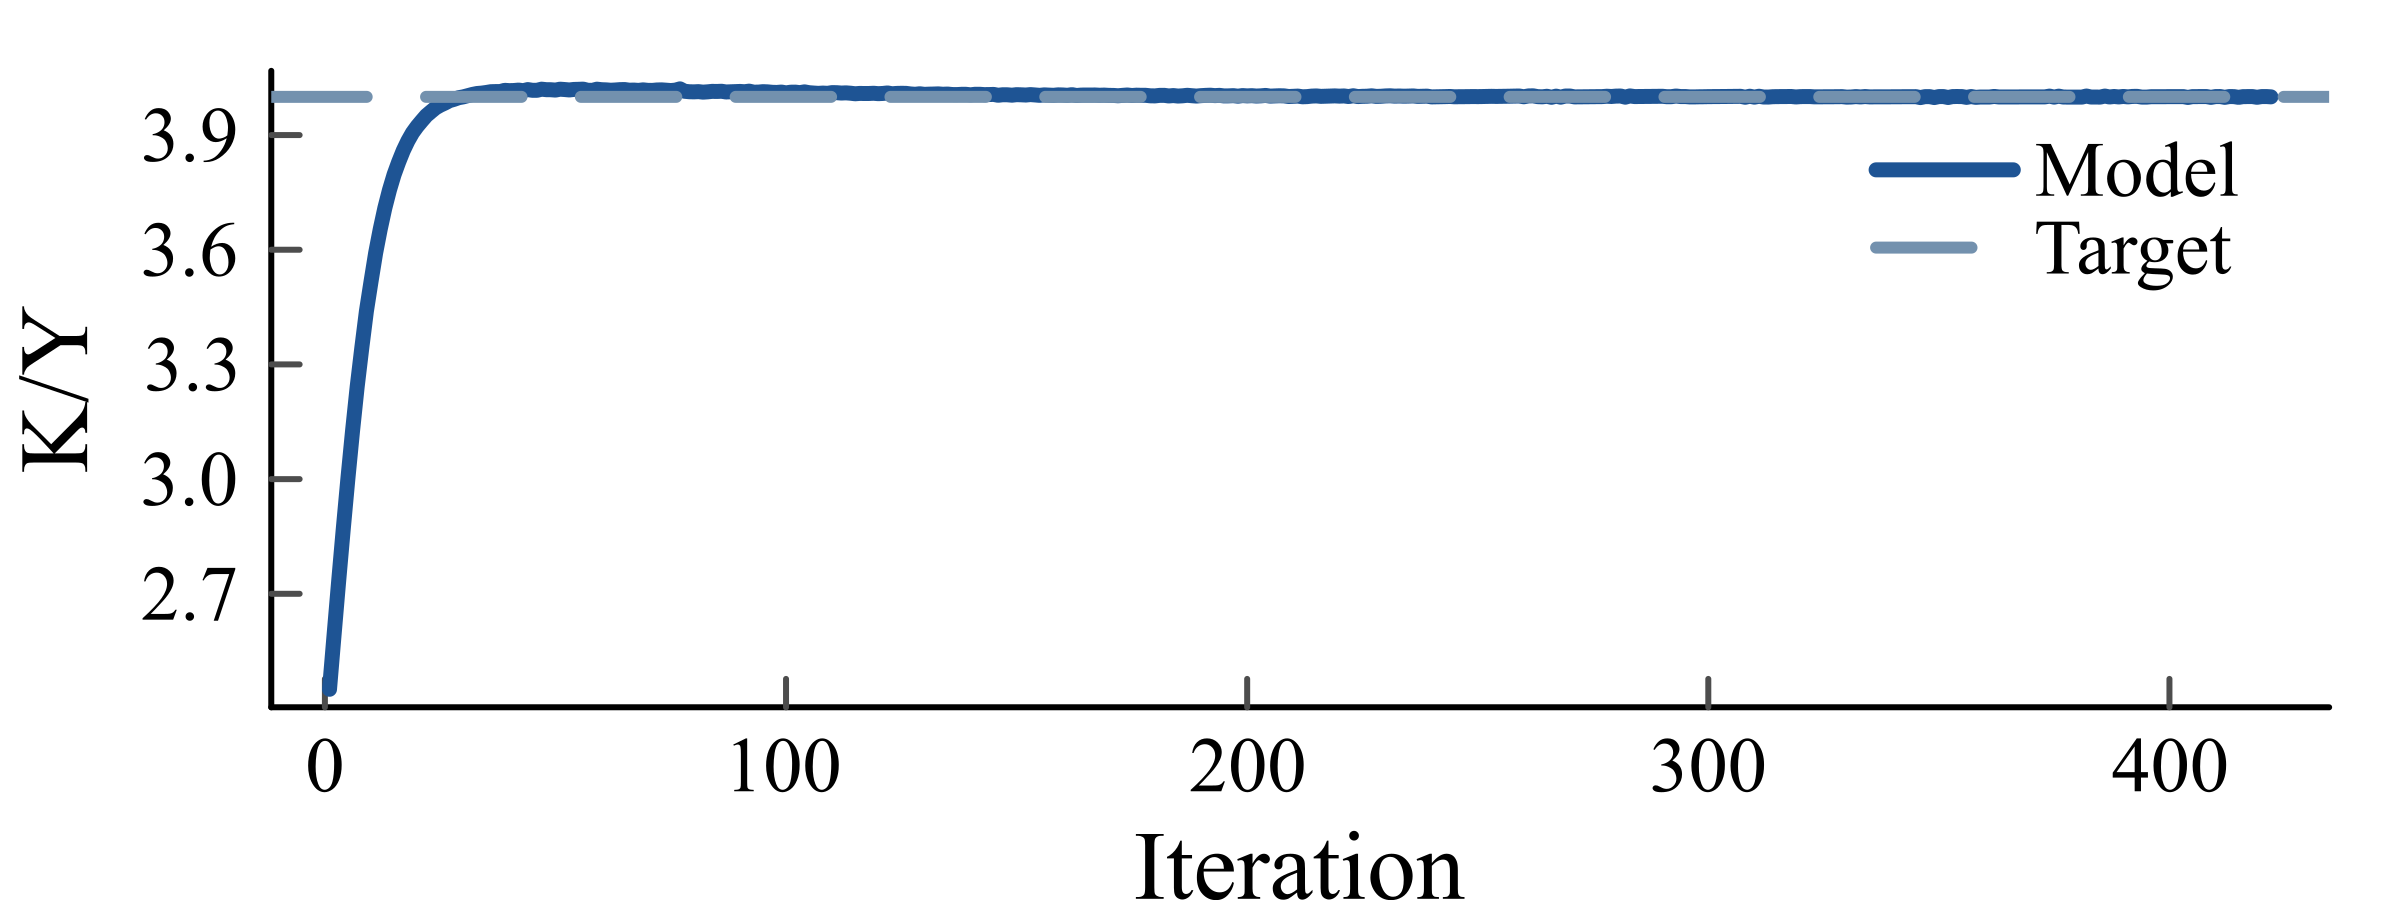

In [30]:
using Plots

# Colors
blue = RGB(0.12, 0.33, 0.58)
blue_gray = RGB(0.45, 0.57, 0.68)

# Plot convergence of targeted moment (K/Y)
plot(1:iter-1, Model_KY[1:iter-1],
    xlabel="Iteration",
    ylabel="K/Y",
    title="",
    lw=2.5,
    lc=blue,
    label="Model",
    dpi=600,
    size=(400, 150),

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,
    legendfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,

    # Legend
    legend=:topright,
    legend_background_color=:transparent,
    legend_foreground_color=:transparent
)

# Target
hline!([Targ_KY],
    lw=2,
    lc=blue_gray,
    ls=:dash,
    label="Target"
)

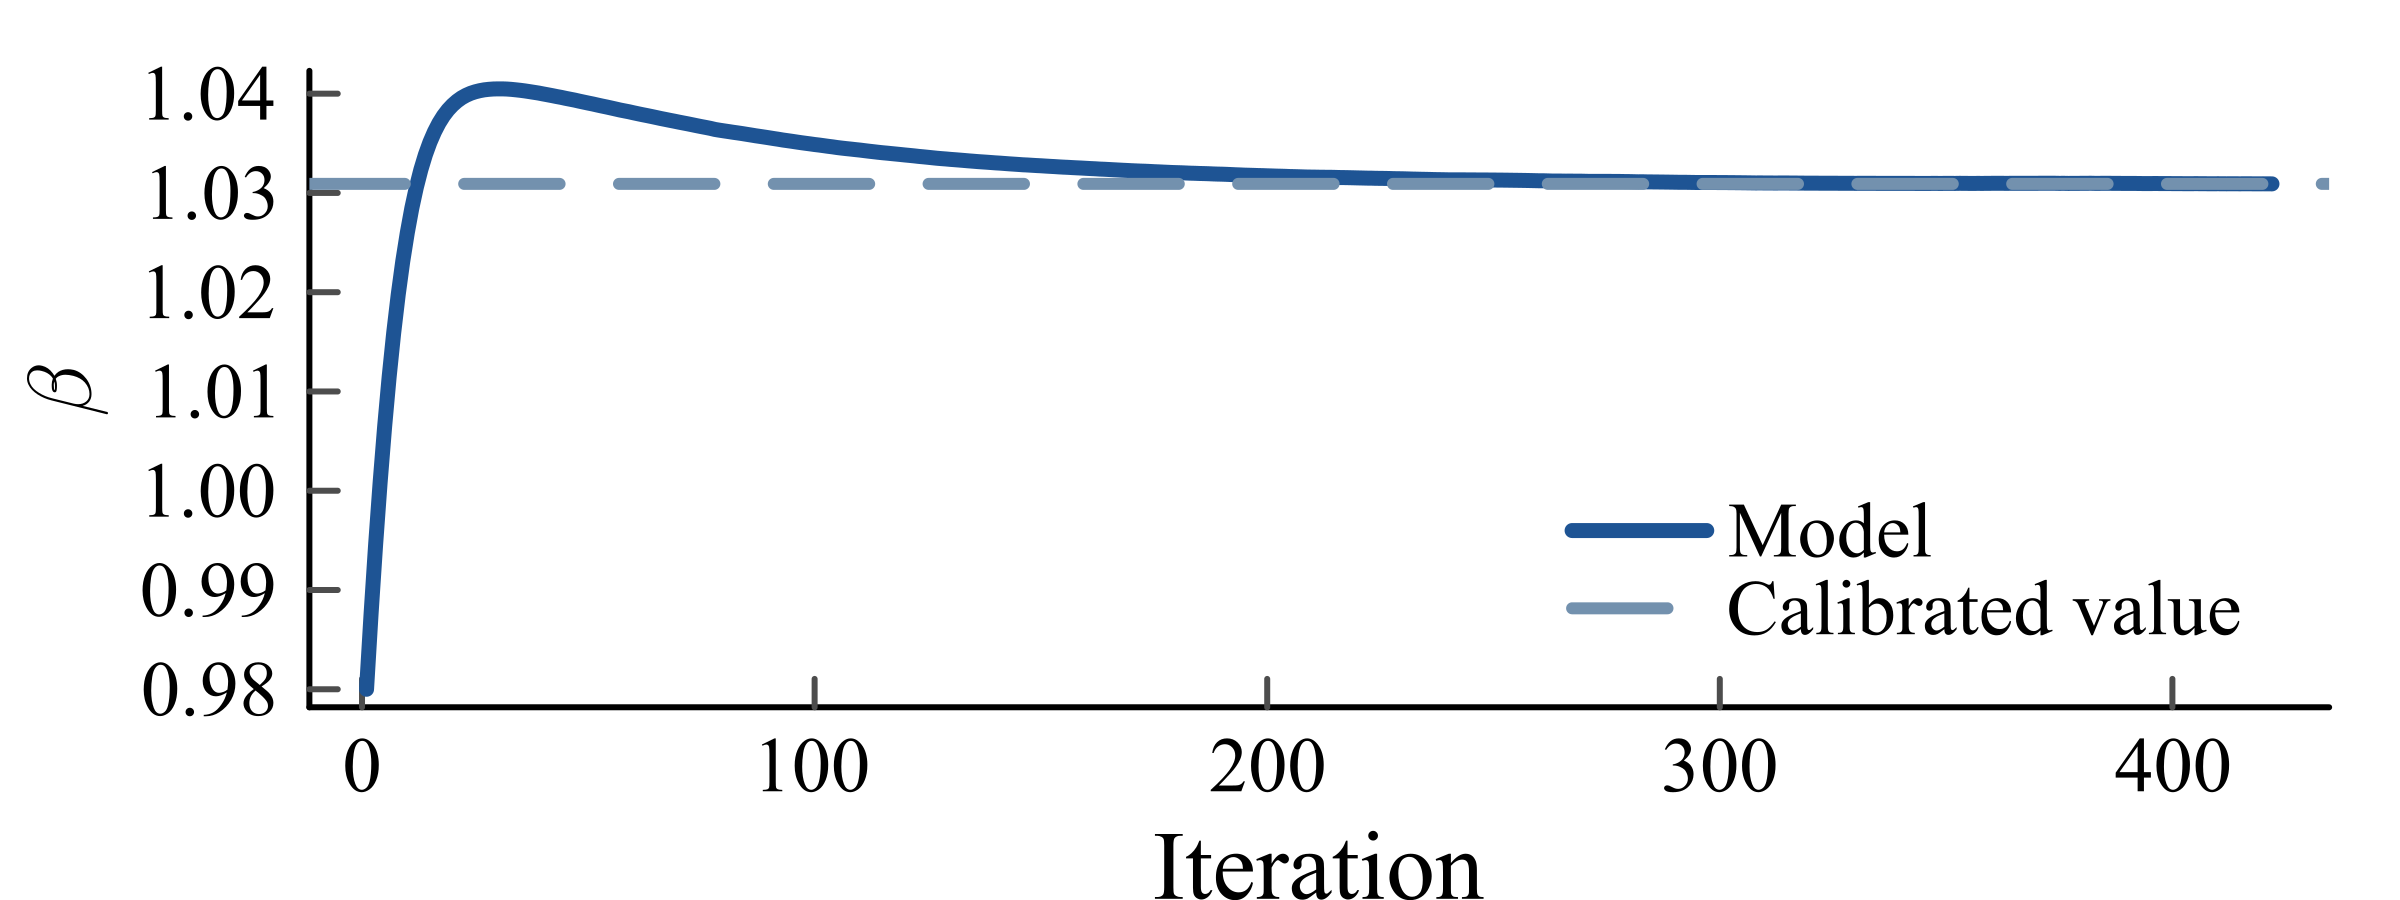

In [34]:
# Convergence of beta
using LaTeXStrings

# Colors
blue = RGB(0.12, 0.33, 0.58)
blue_gray = RGB(0.45, 0.57, 0.68)

# Plot convergence of beta
plot(1:iter-1, β_iter[1:iter-1],
    xlabel="Iteration",
    ylabel=L"\beta",
    title="",
    lw=2.5,
    lc=blue,
    label="Model",
    dpi=600,
    size=(400, 150),

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,
    legendfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,

    # Legend
    legend=:best,
    legend_background_color=:transparent,
    legend_foreground_color=:transparent
)

# Calibrated value
hline!([β],
    lw=2,
    lc=blue_gray,
    ls=:dash,
    label="Calibrated value"
)

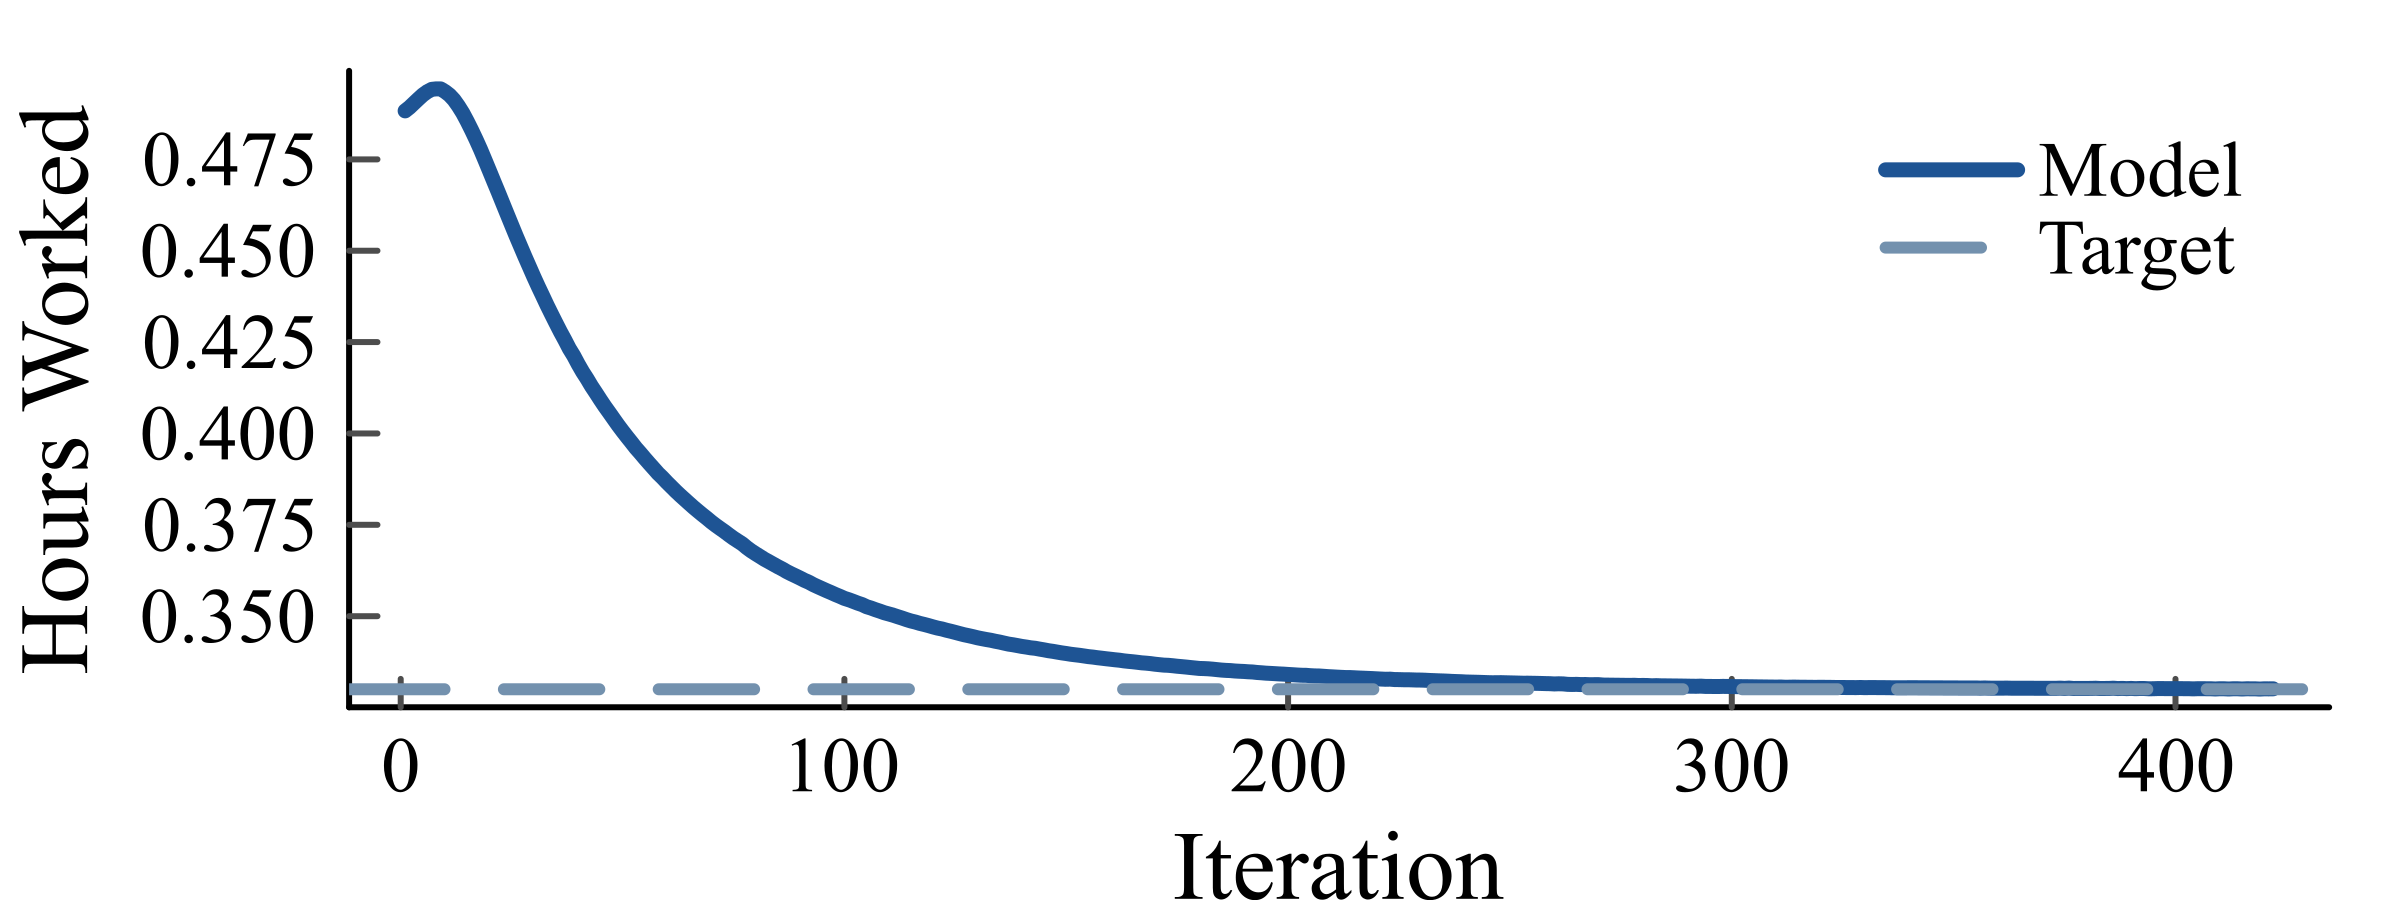

In [ ]:
# Working hours
using Plots

# Colors
blue = RGB(0.12, 0.33, 0.58)
blue_gray = RGB(0.45, 0.57, 0.68)

# Plot convergence of hours worked
plot(1:iter-1, Model_Work[1:iter-1],
    xlabel="Iteration",
    ylabel="Hours Worked",
    title="",
    lw=2.5,
    lc=blue,
    label="Model",
    dpi=600,
    size=(400, 150),

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,
    legendfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,

    # Legend
    legend=:best,
    legend_background_color=:transparent,
    legend_foreground_color=:transparent
)
# Target
hline!([Targ_Work],
    lw=2,
    lc=blue_gray,
    ls=:dash,
    label="Target"
)

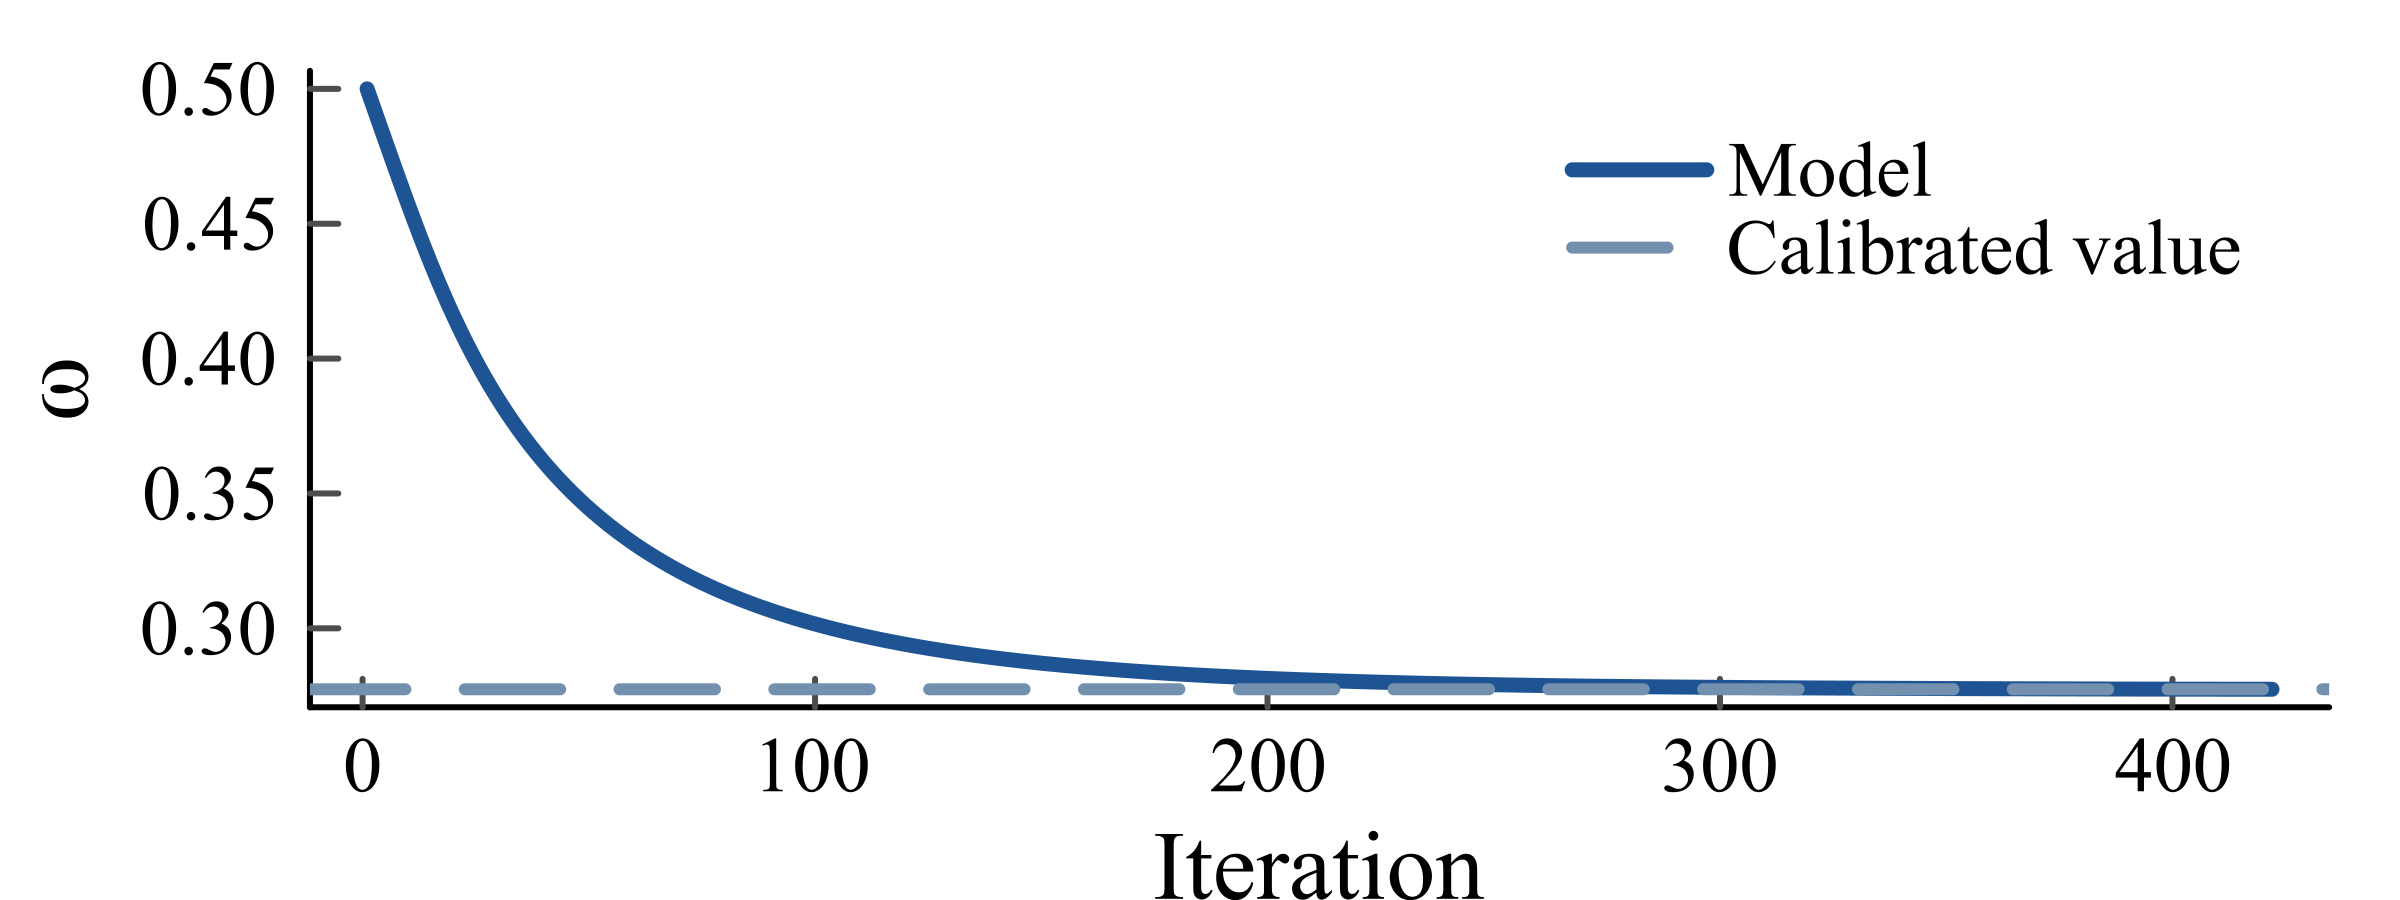

In [37]:
# Convergence of omega
using Plots

# Colors
blue = RGB(0.12, 0.33, 0.58)
blue_gray = RGB(0.45, 0.57, 0.68)

# Plot convergence of omega
plot(1:iter-1, ω_iter[1:iter-1],
    xlabel="Iteration",
    ylabel="ω",
    title="",
    lw=2.5,
    lc=blue,
    label="Model",
    dpi=600,
    size=(400, 150),

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,
    legendfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,

    # Legend
    legend=:best,
    legend_background_color=:transparent,
    legend_foreground_color=:transparent
)

# Calibrated value
hline!([ω],
    lw=2,
    lc=blue_gray,
    ls=:dash,
    label="Calibrated value"
)

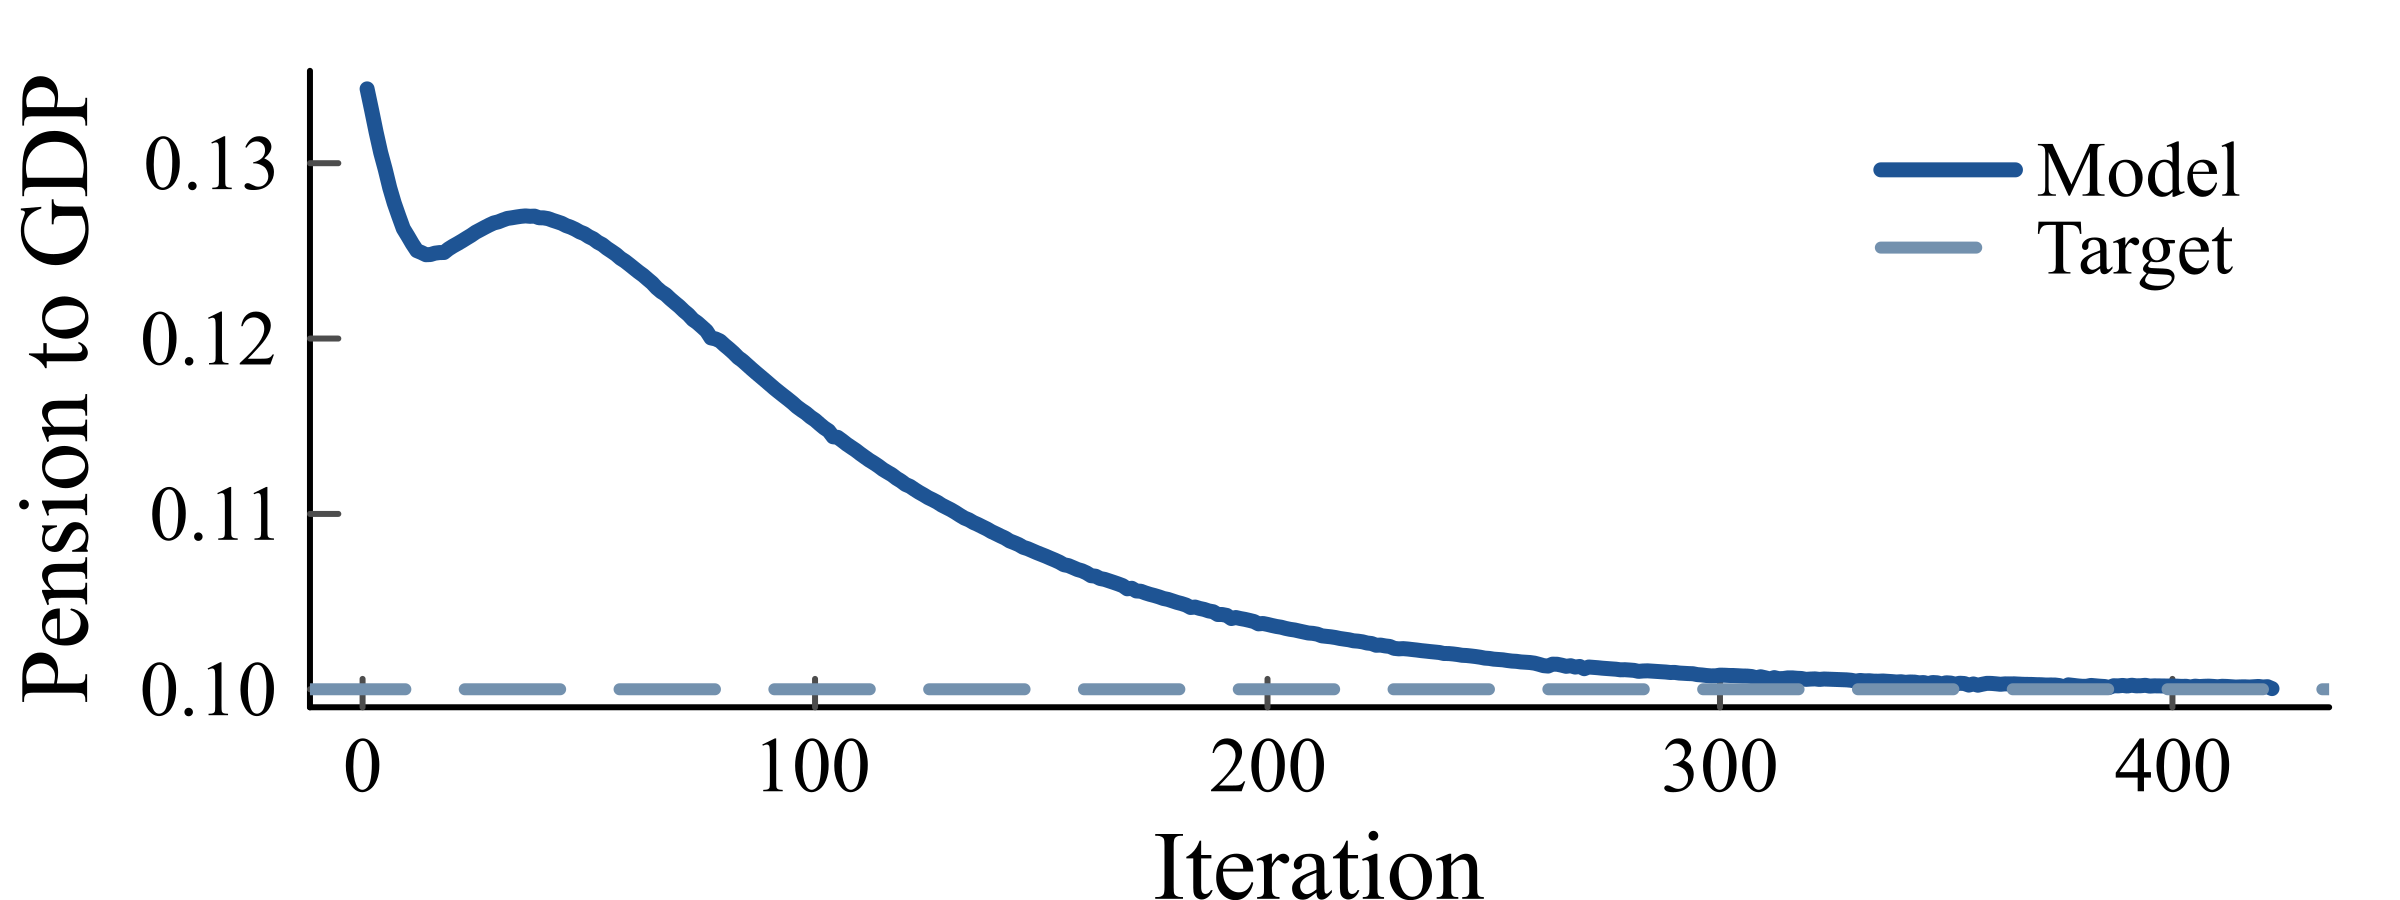

In [38]:
using Plots

# Colors
blue = RGB(0.12, 0.33, 0.58)
blue_gray = RGB(0.45, 0.57, 0.68)

# Plot convergence of pension-to-GDP ratio
plot(1:iter-1, Model_PY[1:iter-1],
    xlabel="Iteration",
    ylabel="Pension to GDP",
    title="",
    lw=2.5,
    lc=blue,
    label="Model",
    dpi=600,
    size=(400, 150),

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,
    legendfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,

    # Legend
    legend=:best,
    legend_background_color=:transparent,
    legend_foreground_color=:transparent
)

# Target
hline!([Targ_PY],
    lw=2,
    lc=blue_gray,
    ls=:dash,
    label="Target"
)

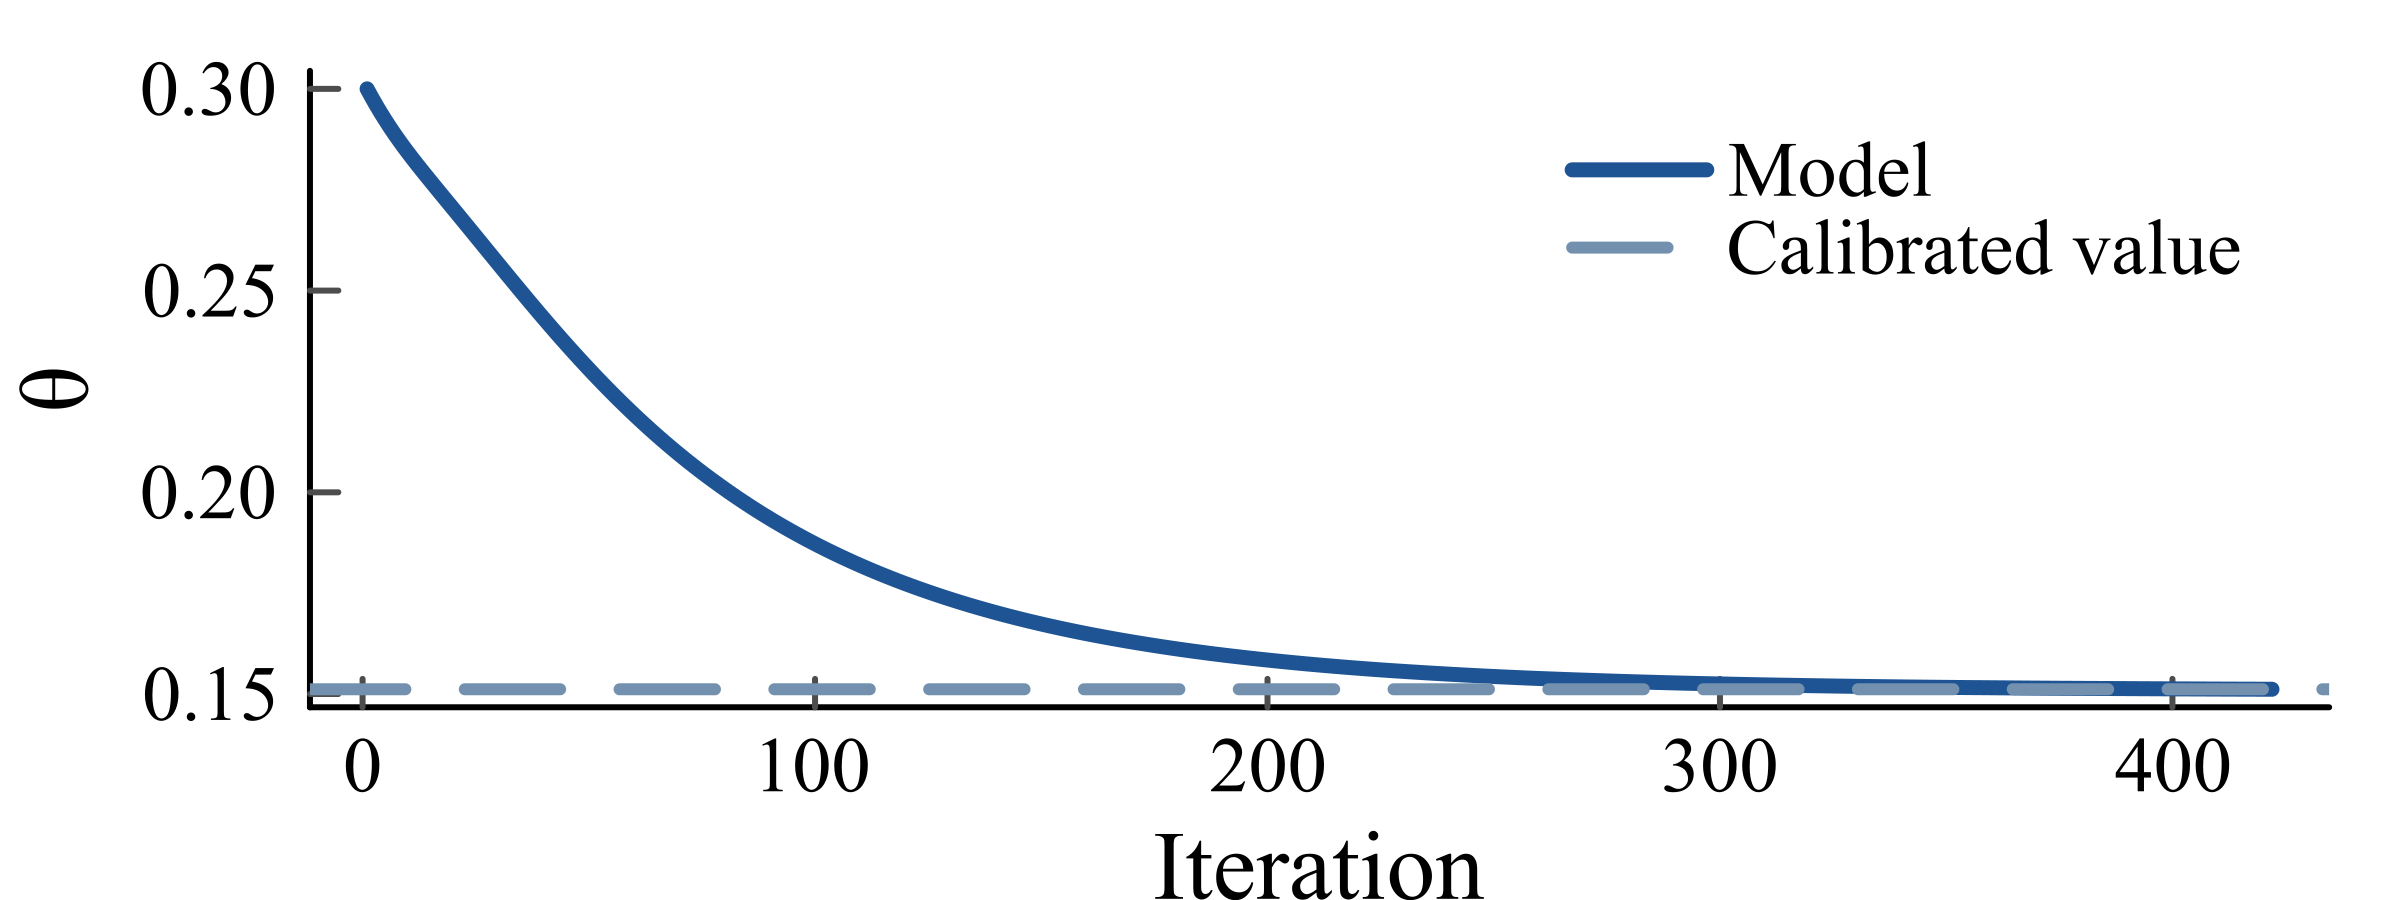

In [39]:
# Convergence of theta
using Plots

# Colors
blue = RGB(0.12, 0.33, 0.58)
blue_gray = RGB(0.45, 0.57, 0.68)

# Plot convergence of theta
plot(1:iter-1, θ_iter[1:iter-1],
    xlabel="Iteration",
    ylabel="θ",
    title="",
    lw=2.5,
    lc=blue,
    label="Model",
    dpi=600,
    size=(400, 150),

    # Fonts
    fontfamily="Times New Roman",
    guidefontsize=10,
    tickfontsize=8,
    legendfontsize=8,

    # Appearance
    background_color=:white,
    foreground_color_axis=:gray30,
    grid=false,
    framestyle=:axes,

    # Legend
    legend=:best,
    legend_background_color=:transparent,
    legend_foreground_color=:transparent
)

# Calibrated value
hline!([θ],
    lw=2,
    lc=blue_gray,
    ls=:dash,
    label="Calibrated value"
)

## A few notes: calibration strategy, algorithm, and identification

In our model so far:
- We have calibrated each parameter to match a particular empirical moment (**one-to-one moment matching**).
- We have specified a convergence criterion for each moment, without explicitly defining a loss function.

However, in some cases (particularly when models become more complicated):
- A single parameter may significantly affect multiple moments, making one-to-one parameter updating difficult.
- The number of empirical moments we want to match may exceed the number of parameters (**overidentification**).

In such cases, it becomes difficult to maintain our current algorithm for updating parameter values.

### Example

Recall that we calibrated:
- $\beta$: Time discount factor, targeting the capital-to-output ratio ($K/Y$).
- $\omega$: Preference parameter governing labor supply, targeting average working hours.

Suppose we are interested in **the effects of pension reform on household savings and consumption**.

- To study this question, we want our model to capture not only aggregate capital accumulation but also the wealth households hold during retirement.
- Thus, we also want to match **average wealth among retired households**.

Assuming that pension generosity $\theta$ is given (calibrated externally in the first step), now we have:
- **Two parameters:** $\boldsymbol{\theta}=(\beta,\omega)$.
- **Three empirical moments:** $K/Y$, average working hours, and average wealth among retirees.

Both parameters potentially affect all three moments, making one-to-one parameter updating difficult. Moreover, with only two parameters, we generally cannot match all three moments exactly (overidentification).

**How should we choose the parameter values?**

### Defining a loss function

One approach is to explicitly define a loss function that measures the distance between model-implied moments and their empirical counterparts.

Let:
- $\boldsymbol{\theta}$: Vector of parameters to calibrate.
- $\mathbf{m}^{model}(\boldsymbol{\theta})$: Vector of model-implied moments.
- $\mathbf{m}^{data}$: Vector of empirical moments.

We choose parameters to minimize:

$$
\boldsymbol{\theta}^*
=
\arg\min_{\boldsymbol{\theta}}
L(\boldsymbol{\theta}),
$$

where

$$
L(\boldsymbol{\theta})
=
\left[
\mathbf{m}^{model}(\boldsymbol{\theta})
-
\mathbf{m}^{data}
\right]'
W
\left[
\mathbf{m}^{model}(\boldsymbol{\theta})
-
\mathbf{m}^{data}
\right].
$$

Here, $W$ is a weighting matrix that determines the relative importance of each moment.

**Example 1: Identity weighting matrix**

If $W=I$, the loss function becomes the sum of squared deviations:

$$
L(\boldsymbol{\theta})
=
\sum_{i=1}^{M}
\left[
m_i^{model}(\boldsymbol{\theta})
-
m_i^{data}
\right]^2.
$$

**Example 2: Squared percentage deviations**

Alternatively, we can minimize the sum of squared percentage deviations:

$$
L(\boldsymbol{\theta})
=
\sum_{i=1}^{M}
\left[
\frac{
m_i^{model}(\boldsymbol{\theta})
-
m_i^{data}
}{
m_i^{data}
}
\right]^2.
$$

This specification is useful when empirical moments have different units or magnitudes (assuming the targets are nonzero).

### Implementation

How do we find the parameters that minimize the loss function?

1. Construct a function that takes parameter values $\boldsymbol{\theta}$ as inputs and returns the loss $L(\boldsymbol{\theta})$.
    - Solve the model given $\boldsymbol{\theta}$.
    - Compute the model-implied moments.
    - Evaluate the loss function.

2. Use a numerical optimizer to find the parameter values that minimize the loss.
    - For example, we can use `Optim.jl` in Julia, with algorithms such as Nelder–Mead or BFGS.

What algorithms do these optimization routines use? Are there any important considerations when implementing them? We will study some of these algorithms and their practical implementation later in the course!

### Exercise: Do parameter values matter for the quantitative results of counterfactual analysis?

An important motivation for calibration (choosing parameter values so that the model replicates a set of relevant empirical moments) is to make the model's quantitative predictions more credible.

Therefore, in this exercise, we would like to ask: how much do parameter values matter for counterfactual results?

A simple way to investigate this is to compare counterfactual results obtained using:
- **Calibrated parameter values** from this lecture.
- **Arbitrarily assigned parameter values** from the previous lecture.

Consider the experiment in which **life expectancy increases by 10 years**.

Conduct this counterfactual experiment using the calibrated model and compare the results with those obtained in the previous lecture.

**How different are the quantitative predictions?**

In [42]:
# Baseline
r0=0.02; w0=1.0; τ0=0.1;
~,~,~,K,H,τ = solve_GE(r0,w0,τ0,p)
GDP = K^(p.α) * H^(1-p.α); r = p.α * (K/H)^(p.α-1) - p.δ; w = (1-p.α) * (K/H)^(p.α);

In [45]:
# compute stationary equilibrium with new J
J_long = 70
muj_long = fill(1.0/J_long, J_long)
p_long = Parameters(β, σ, ω, θ, α, δ, J_long, JR, muj_long) # update parameter struct

r0=r; w0=w; τ0=τ;
~,~,~,K_long,H_long,τ_long = solve_GE(r0,w0,τ0,p_long)
GDP_long = K_long^(p_long.α) * H_long^(1-p_long.α);
r_long = p_long.α * (K_long/H_long)^(p_long.α-1) - p_long.δ;
w_long = (1-p_long.α) * (K_long/H_long)^(p_long.α);

In [48]:
# display and compare the results 
using DataFrames

results_long = DataFrame(
    Variable = ["GDP", "Capital", "Labor", "Interest rate", "Wage", "Tax rate"],
    Baseline = round.([GDP, K, H, r, w, τ], digits=3),
    Aging    = round.([GDP_long, K_long, H_long, r_long, w_long, τ_long], digits=3),
    Change   = round.([
        100 * (GDP_long / GDP - 1),
        100 * (K_long / K - 1),
        100 * (H_long / H - 1),
        100 * (r_long - r),
        100 * (w_long / w - 1),
        100 * (τ_long - τ)
    ], digits=3),
    Unit = ["%", "%", "%", "pp", "%", "pp"]
)

show(results_long; eltypes=false)

6×5 DataFrame
 Row │ Variable       Baseline  Aging   Change  Unit 
─────┼───────────────────────────────────────────────
   1 │ GDP               0.493   0.451  -8.439  %
   2 │ Capital           1.971   1.853  -5.998  %
   3 │ Labor             0.249   0.225  -9.618  %
   4 │ Interest rate    -0.018  -0.02   -0.214  pp
   5 │ Wage              1.326   1.344   1.304  %
   6 │ Tax rate          0.149   0.23    8.101  pp